# WTI Crude-Oil Forecasting — Demo

## 1. Setup

In [2]:
import sys
from pathlib import Path

# Make 'src' importable whether this runs from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from src.data import build_dataset, coverage, weekly_history, SPLITS, HORIZON

## 2. Load data

In [3]:
daily, weekly = build_dataset(save=True)   # also writes data/processed/daily.csv and weekly.csv

print(f"{len(daily):,} trading days, {daily.index.min().date()} to {daily.index.max().date()}")
daily[daily["usable"]].head()

4,484 trading days, 2009-01-02 to 2026-10-20


,wti_raw,wti,wti_filled,brent,f1,f2,f3,f4,weekly_week_end,crude_production,refinery_crude_input,refinery_utilization,commercial_crude_stocks,crude_net_imports,target_date,wti_target,split,usable
date,,,,,,,,,,,,,,,,,,
2010-01-04,81.52,81.52,False,79.05,81.51,82.12,82.65,83.12,2009-12-25,5512.0,13879,80.3,307969,7995.0,2010-02-02,77.21,train,True
2010-01-05,81.74,81.74,False,79.27,81.77,82.41,82.99,83.52,2009-12-25,5512.0,13879,80.3,307969,7995.0,2010-02-03,76.96,train,True
2010-01-06,83.12,83.12,False,80.14,83.18,83.75,84.31,84.86,2010-01-01,5507.0,13792,79.9,306626,8323.0,2010-02-04,73.13,train,True
2010-01-07,82.60,82.60,False,80.57,82.66,83.19,83.75,84.29,2010-01-01,5507.0,13792,79.9,306626,8323.0,2010-02-05,71.15,train,True
2010-01-08,82.74,82.74,False,80.06,82.75,83.30,83.87,84.47,2010-01-01,5507.0,13792,79.9,306626,8323.0,2010-02-08,71.87,train,True


**Table organization**

- **Daily:** WTI spot (the target), Brent spot, and NYMEX futures contracts 1-4. Short gaps are filled from the past only.
- **Weekly:** crude production, refinery crude input, refinery utilization, commercial crude stocks, and crude net imports. Each value enters on the date EIA *released* it (the Wednesday after the week ends, later in holiday weeks), never earlier, so there is no look-ahead.
- **Target:** `wti_target` is the WTI spot price 20 trading days after each date. A row is `usable` only if its target is observed and falls in the same split, so no target leaks across a split boundary.

**Known data issues**

- The EIA stopped publishing data after **2024-04-05** so the futures columns are empty for most of the validation period (Jan. 2024 - Aug. 2025) and all of test (Sept. 2025 - Aug. 2026).
- There is a major outlier where WTI spot was **-$36.98 on 2020-04-20**.
- EIA's WTI spot series is missing about 38 trading days in April-July 2011. Currently, inputs are filled from the past on those days and the target is left missing.

In [4]:
coverage(daily)

,first,last,missing_since_2010
wti,2009-01-02,2026-10-20,0.0%
brent,2009-01-02,2026-10-20,0.0%
f1,2009-01-02,2024-04-05,15.0%
f2,2009-01-02,2024-04-05,15.0%
f3,2009-01-02,2024-04-05,15.0%
f4,2009-01-02,2024-04-05,15.0%
crude_production,2009-01-02,2026-10-20,0.0%
refinery_crude_input,2009-01-02,2026-10-20,0.0%
refinery_utilization,2009-01-02,2026-10-20,0.0%
commercial_crude_stocks,2009-01-02,2026-10-20,0.0%


In [5]:
# Forecast origins per split, and how many have an observed, same-split target
daily.groupby("split")["usable"].agg(rows="size", usable="sum").reindex(list(SPLITS))

,rows,usable
split,,
train,3533,3441
val,415,395
test,249,229
live,35,15


In [6]:
# What the models will see for the weekly inputs: the last 12 weeks released by the latest date
weekly_history(weekly, daily.index.max())

,release_date,crude_production,refinery_crude_input,refinery_utilization,commercial_crude_stocks,crude_net_imports
week_end,,,,,,
2026-07-24,2026-07-29,13796.0,17336,97.2,404508,2216.0
2026-07-31,2026-08-05,13804.0,17153,96.5,406987,2513.0
2026-08-07,2026-08-12,13805.0,17179,96.2,424410,4281.0
2026-08-14,2026-08-19,13830.0,17395,97.2,428815,2527.0
2026-08-21,2026-08-26,13843.0,17393,97.4,428910,2366.0
2026-08-28,2026-09-02,13862.0,17496,98.0,424460,2287.0
2026-09-04,2026-09-10,13947.0,17586,97.8,424069,3407.0
2026-09-11,2026-09-16,13944.0,17330,96.8,423429,2227.0
2026-09-18,2026-09-23,13939.0,16811,94.0,426398,2596.0


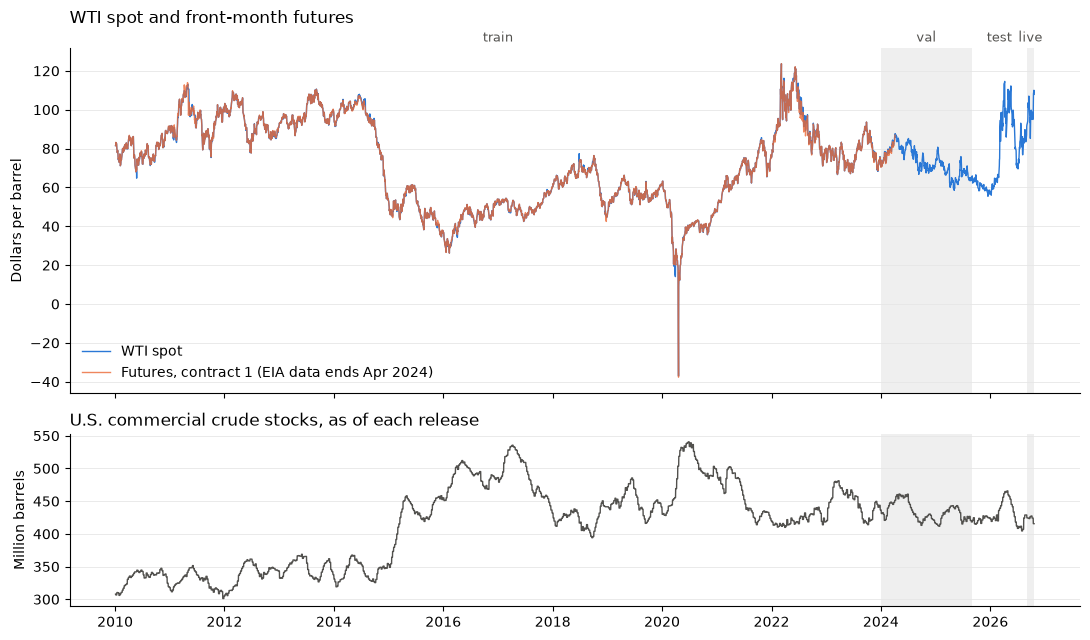

In [7]:
plot_data = daily.loc["2010":]
end = daily.index.max()

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [2, 1]})

ax.plot(plot_data.index, plot_data["wti"], lw=1, color="#2a78d6", label="WTI spot")
ax.plot(plot_data.index, plot_data["f1"], lw=1, color="#eb6834", alpha=0.8,
        label="Futures, contract 1 (EIA data ends Apr 2024)")

# Shade the evaluation periods and label every split
for i, (name, (start, stop)) in enumerate(SPLITS.items()):
    start, stop = pd.Timestamp(start), min(pd.Timestamp(stop), end)
    if i % 2 == 1:
        for a in (ax, ax2):
            a.axvspan(start, stop, color="0.5", alpha=0.12, lw=0)
    ax.text(start + (stop - start) / 2, 1.01, name, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9, color="#52514e")

ax.set_ylabel("Dollars per barrel")
ax.set_title("WTI spot and front-month futures", loc="left", pad=18)
ax.legend(loc="lower left", frameon=False)

ax2.plot(plot_data.index, plot_data["commercial_crude_stocks"] / 1000, lw=1, color="#52514e")
ax2.set_ylabel("Million barrels")
ax2.set_title("U.S. commercial crude stocks, as of each release", loc="left")

for a in (ax, ax2):
    a.grid(axis="y", color="0.9", lw=0.6)
    a.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "wti_overview.png", dpi=150)
plt.show()

## 3. Baselines: persistence and futures

Two simple forecasts that every model has to beat:

- **Persistence:** WTI in 20 trading days = WTI today.
- **Futures:** WTI in 20 trading days = today's price of a NYMEX futures contract. `f1` is the nearest delivery month and `f2` the one after.

Scored on usable rows in train and validation only. Errors are measured in dollars per barrel, and `coverage` is the share of the split's usable rows that have a forecast.

In [8]:
from src.baselines import persistence_forecast, futures_forecast
from src.evaluate import compare

baselines = {
    "persistence": persistence_forecast(daily),
    "futures_f1": futures_forecast(daily, "f1"),
    "futures_f2": futures_forecast(daily, "f2"),
}

def show(table):
    """Round the errors and show coverage and direction as percentages."""
    pct = lambda col: table[col].map(lambda x: "" if pd.isna(x) else f"{x:.0%}")
    return table.round(2).assign(coverage=pct("coverage"), direction=pct("direction"))

show(compare(daily, baselines))

n coverage   MAE  RMSE direction
split model                                           
train persistence  3441     100%  5.23  6.89          
      futures_f1   3441     100%  5.16  6.83       55%
      futures_f2   3441     100%  5.03  6.64       56%
val   persistence   395     100%  4.06  4.84          
      futures_f1     66      17%  4.34  4.92       12%
      futures_f2     66      17%  4.60  5.17       12%

In [9]:
# Same comparison, scored only on days where every baseline has a forecast
show(compare(daily, baselines, same_rows=True))

n coverage   MAE  RMSE direction
split model                                           
train persistence  3441     100%  5.23  6.89          
      futures_f1   3441     100%  5.16  6.83       55%
      futures_f2   3441     100%  5.03  6.64       56%
val   persistence    66      17%  3.88  4.47          
      futures_f1     66      17%  4.34  4.92       12%
      futures_f2     66      17%  4.60  5.17       12%

**Open items**

- **Futures after April 2024.** EIA's futures data ends on 2024-04-05, so the futures baseline covers only the first three months of validation and none of test. We need a newer source before the main comparison can run.
- **Which contract.** The proposal uses the contract whose delivery month is closest to the target date. That rule is stubbed in `src/baselines.py` (`futures_closest_contract`); until it's built, `f1` and `f2` are shown side by side.

## 4. LSTM forecasts

A small LSTM reads the last 60 trading days of WTI, Brent and the five weekly supply series (about the last 12 weekly reports) and predicts the **20-day change** in WTI. The forecast is today's price plus that change, so "no change" is exactly the persistence baseline.

- **Input:** 60 days × 7 features, standardized with training-set statistics. Futures are left out because they're missing after April 2024.
- **Model:** one LSTM layer (16 hidden units) and a linear layer on the last step.
- **Loss / optimizer:** mean squared error, Adam (learning rate 1e-4).
- Training keeps the epoch with the lowest validation loss, so the validation score is slightly optimistic. Test is the honest check later.

4,080 samples, each (60, 7) (days, features)


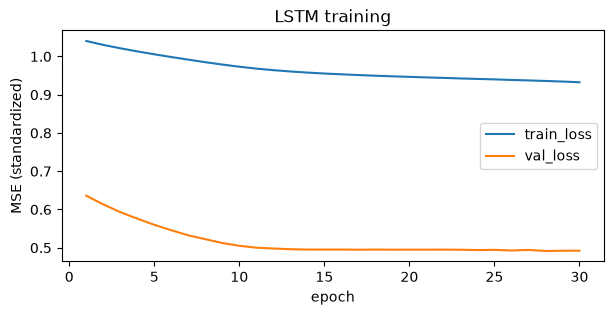

In [10]:
from src.lstm_model import make_windows, fit_lstm, lstm_forecast

data = make_windows(daily)
print(f"{len(data['X']):,} samples, each {tuple(data['X'].shape[1:])} (days, features)")

model, history = fit_lstm(data, hidden=16, lr=1e-4, epochs=30)
lstm = lstm_forecast(model, data)

history.plot(title="LSTM training", xlabel="epoch", ylabel="MSE (standardized)", figsize=(7, 3));

In [11]:
show(compare(daily, {**baselines, "lstm": lstm}))

n coverage   MAE  RMSE direction
split model                                           
train persistence  3441     100%  5.23  6.89          
      futures_f1   3441     100%  5.16  6.83       55%
      futures_f2   3441     100%  5.03  6.64       56%
      lstm         3441     100%  5.03  6.66       59%
val   persistence   395     100%  4.06  4.84          
      futures_f1     66      17%  4.34  4.92       12%
      futures_f2     66      17%  4.60  5.17       12%
      lstm          395     100%  3.95  4.83       61%

In [12]:
# The proposal's small grid: hidden size × learning rate, compared on validation MAE
grid = []
for hidden in (16, 32):
    for lr in (1e-3, 1e-4):
        m, h = fit_lstm(data, hidden=hidden, lr=lr)
        scores = compare(daily, {"lstm": lstm_forecast(m, data)}, splits=["val"])
        grid.append({"hidden": hidden, "lr": lr, "best_epoch": h["val_loss"].idxmin(),
                     "val_MAE": round(scores["MAE"].iloc[0], 2)})
pd.DataFrame(grid)

,hidden,lr,best_epoch,val_MAE
0,16,0.0010,4,3.93
1,16,0.0001,28,3.95
2,32,0.0010,1,3.96
3,32,0.0001,7,3.98


**What we see so far**

- The LSTM beats persistence on validation by about 0.10 cents/barrel MAE, and every setting in the grid lands within a few cents of that. It's a small edge, and validation also picked the epoch, so it's a hint rather than proof.
- At a learning rate of 1e-3 it overfits within an epoch or two (training loss keeps falling while validation loss rises). At 1e-4 both fall together.
- Its forecasts are cautious: a typical predicted 20-day move is under 2 dollars, while real 20-day moves in validation vary by about 5 dollars. So far it's mostly a careful adjustment to persistence.
- Next: dropout or weight decay, trying fewer features, and checking which inputs it actually uses.

## 5. LLM forecasts

A frozen LLM (**gpt-5.4-mini**, used as-is through the OpenAI API) gets the same information as the LSTM, written as text: the last 60 trading days of WTI and Brent, plus the last 12 weekly EIA reports released by the forecast date. It replies with a forecast and a one-sentence reason, in JSON. Nothing is trained.

- **Look-ahead risk:** the model's knowledge runs to **August 31, 2025**, which covers all of validation, so it may remember what oil actually did. The prompt uses relative days ("day −59 … day 0") instead of calendar dates, but price levels can still hint at the period. Test (from September 2025) is after its cutoff, so that's the honest check later.
- **Sample:** one forecast date every 20 trading days, so the 20 forecasts' windows don't overlap.
- **Cost:** a few cents. Every reply is saved in `results/llm_logs/`, so re-running the notebook is free.

In [13]:
from src.llm_forecast import build_prompt, sample_dates, llm_forecasts

dates = sample_dates(daily, "val")
print(f"{len(dates)} forecast dates, {dates[0].date()} to {dates[-1].date()}\n")
print(build_prompt(daily, weekly, dates[0]))   # exactly what the model sees

20 forecast dates, 2024-01-02 to 2025-07-14

Day 0 is today. Recent market data is below, oldest first.

Daily spot prices ($/barrel), last 60 trading days:
day,WTI,Brent
-59,82.83,87.86
-58,82.83,91.37
-57,85.89,90.70
-56,83.70,87.58
-55,82.87,88.40
-54,87.67,94.33
-53,86.65,90.99
-52,86.66,92.52
-51,88.35,91.99
-50,89.35,93.12
-49,89.12,93.72
-48,85.49,91.88
-47,84.58,88.00
-46,86.07,90.14
-45,83.80,88.45
-44,86.04,90.73
-43,83.03,90.73
-42,81.64,86.82
-41,81.05,86.92
-40,83.04,89.02
-39,81.19,87.55
-38,81.54,87.31
-37,77.96,83.43
-36,75.85,81.46
-35,76.34,81.74
-34,76.34,83.66
-33,78.86,84.09
-32,78.90,84.20
-31,77.15,82.40
-30,73.50,77.73
-29,76.47,81.22
-28,78.10,83.25
-27,78.35,82.42
-26,76.80,81.76
-25,74.83,79.82
-24,74.46,79.49
-23,76.09,81.66
-22,77.56,82.98
-21,75.66,81.72
-20,73.70,78.72
-19,72.73,78.16
-18,71.95,77.27
-17,68.98,74.33
-16,69.00,74.21
-15,70.87,75.94
-14,70.95,75.75
-13,68.27,74.11
-12,69.09,74.14
-11,71.21,77.05
-10,71.05,76.84
-9,72.16,78.89
-8,73.23,79.82

In [14]:
llm = llm_forecasts(daily, weekly, dates)   # first run calls the API; later runs read results/llm_logs/

# Scored only on these dates, so all three are compared on the same days
show(compare(daily, {"persistence": baselines["persistence"], "lstm": lstm, "llm": llm["forecast"]},
             splits=["val"], same_rows=True))

20 forecasts: 20 from saved logs, 0 new (0 input / 0 output tokens)


n coverage   MAE  RMSE direction
split model                                         
val   persistence  20       5%  3.72  4.37          
      lstm         20       5%  3.78  4.42       55%
      llm          20       5%  3.75  4.50       55%

In [15]:
# Each forecast next to today's price, what actually happened, and the model's reason
pd.set_option("display.max_colwidth", 160)
llm.assign(today=daily["wti"], actual=daily["wti_target"])[["today", "forecast", "actual", "reason"]].round(2)

,today,forecast,actual,reason
date,,,,
2024-01-02,70.62,73.2,76.28,"WTI has fallen sharply into the low 70s, but rising refinery runs and a draw in crude stocks should support a modest rebound over the next month."
2024-01-31,76.28,75.8,79.22,WTI has eased from the recent high and today’s softer refinery utilization and crude input point to a modestly lower price over the next four weeks.
2024-02-29,79.22,81.2,83.96,"WTI has strong recent momentum, but rising stocks and weaker refinery runs should limit gains over the next month."
2024-03-28,83.96,86.2,85.38,"WTI has strong upward momentum, while rising refinery runs support demand but still-high crude stocks cap the upside."
2024-04-26,85.38,87.0,78.48,"WTI is trending higher with strong refinery runs and slightly lower stocks, suggesting a modest gain over the next month."
2024-05-24,78.48,79.5,81.97,"WTI has stabilized near $78-$80 after a sharp decline, while refinery runs and utilization are rising and inventories are broadly steady, suggesting a modes..."
2024-06-25,81.97,83.2,78.78,WTI has been trending up over the last month and current EIA data are broadly supportive but not tight enough to imply a large breakout.
2024-07-24,78.78,80.5,72.76,"Recent WTI weakness may partly reverse as crude stocks continue to draw, keeping prices near the low $80s."
2024-08-21,72.76,74.5,72.86,"WTI has fallen sharply in recent days, but declining crude stocks and firmer refinery runs suggest a modest rebound over the next four weeks."


## 6. Results: MAE, RMSE, disagreement plots

Every model on validation, side by side. **direction** is the share of forecasts that called the move (up or down) correctly; it's blank for persistence, which never predicts a move. The LLM only forecast 20 dates (see `coverage`), so section 5 compares it with the others on exactly those days.

In [16]:
models = {
    "persistence": baselines["persistence"],
    "futures_f2": baselines["futures_f2"],
    "lstm": lstm,
    "llm": llm["forecast"],
}
show(compare(daily, models, splits=["val"]))

n coverage   MAE  RMSE direction
split model                                          
val   persistence  395     100%  4.06  4.84          
      futures_f2    66      17%  4.60  5.17       12%
      lstm         395     100%  3.95  4.83       61%
      llm           20       5%  3.75  4.50       55%

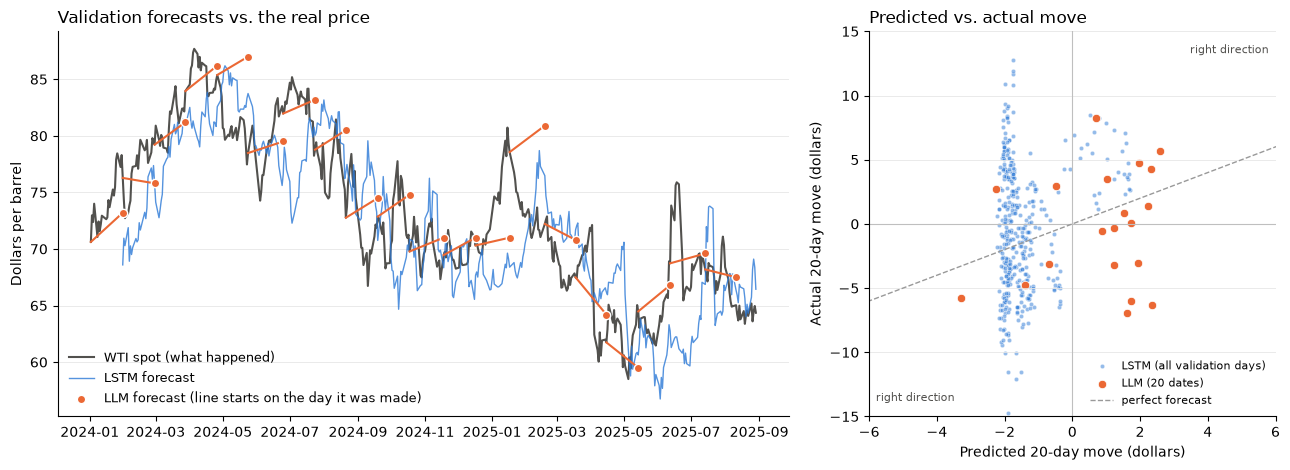

In [17]:
# Left: each forecast drawn from the day it was made to the day it was aiming at.
# Right: the move each model predicted against the move that actually happened.
val = daily[daily["usable"] & (daily["split"] == "val")]
lstm_val = lstm.reindex(val.index)
GRAY, BLUE, ORANGE = "#52514e", "#2a78d6", "#eb6834"

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.8, 1]})

actual = daily.loc[val.index.min():val["target_date"].max(), "wti"]
ax.plot(actual.index, actual, lw=1.5, color=GRAY, label="WTI spot (what happened)")
ax.plot(val["target_date"], lstm_val, lw=1, color=BLUE, alpha=0.8, label="LSTM forecast")
for date, f in llm["forecast"].items():
    ax.plot([date, daily.at[date, "target_date"]], [daily.at[date, "wti"], f], lw=1.5, color=ORANGE)
ax.scatter(llm.index.map(daily["target_date"]), llm["forecast"], s=36, color=ORANGE,
           edgecolor="white", linewidth=1, zorder=3, label="LLM forecast (line starts on the day it was made)")
ax.set_ylabel("Dollars per barrel")
ax.set_title("Validation forecasts vs. the real price", loc="left")
ax.legend(loc="lower left", frameon=False, fontsize=9)

for name, f, color, size, alpha in [("LSTM (all validation days)", lstm_val, BLUE, 10, 0.5),
                                    ("LLM (20 dates)", llm["forecast"], ORANGE, 36, 1.0)]:
    rows = val.loc[f.dropna().index]
    ax2.scatter(f.loc[rows.index] - rows["wti"], rows["wti_target"] - rows["wti"], s=size, color=color,
                alpha=alpha, edgecolor="white", linewidth=0.5, label=name)
ax2.axhline(0, color="0.75", lw=0.8)
ax2.axvline(0, color="0.75", lw=0.8)
ax2.plot([-15, 15], [-15, 15], ls="--", lw=1, color="0.6", label="perfect forecast")
ax2.set(xlim=(-6, 6), ylim=(-15, 15), xlabel="Predicted 20-day move (dollars)", ylabel="Actual 20-day move (dollars)")
for x, y in [(5.8, 14), (-5.8, -14)]:
    ax2.text(x, y, "right direction", ha="right" if x > 0 else "left", va="top" if y > 0 else "bottom",
             fontsize=8, color=GRAY)
ax2.set_title("Predicted vs. actual move", loc="left")
ax2.legend(loc="lower right", frameon=False, fontsize=8)

for a in (ax, ax2):
    a.grid(axis="y", color="0.9", lw=0.6)
    a.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "val_forecasts.png", dpi=150)
plt.show()

**Findings so far (validation, January 2024 – August 2025)**

1. **Nothing clearly beats "no change" yet.** On the 20 dates every model forecast, persistence, the LSTM and the LLM are within 6 cents of each other (MAE about 3.7 dollars per barrel). Over all validation days the LSTM edges persistence by about 10 cents, which is a hint, not proof. A one-month oil price is very hard to forecast, so this is the bar the second half of the project has to clear.
2. **The two models lean in opposite directions.** The LSTM predicted a fall on more than 90% of validation days (about 60% in training), while the LLM predicted a rise on 15 of 20 dates. The real price fell on about half the days. One likely reason for the LSTM: on half the validation days, U.S. crude production is higher than anything it saw in training.
3. **The LLM's reasons sound convincing but carry little signal.** It cites momentum after prices rise and a rebound after they fall, and it gets the direction right 11 times out of 20. There's no sign it remembers 2024–25 prices, which would have made it far more accurate.
4. **Futures can't be judged yet.** Their data ends on 2024-04-05, so they cover only the first three months of validation. In those months the futures curve pointed down while the price rose, but that's one market episode, not a pattern.

**Next steps**

- Find a futures source from April 2024 on (ask the TA, or the library about Bloomberg/LSEG), and build the proposal's "closest delivery month" rule.
- Run the LLM on more dates and on the test period, which is after its knowledge cutoff. Compare prompts with and without calendar dates to test whether it remembers prices.
- LSTM: dropout or weight decay, fewer features, and inputs that stay in range (for example, weekly changes instead of levels).
- Score every model once on test when they're final.